In [26]:
import pandas as pd

df = pd.read_excel("C:\\Users\\DELL\\Downloads\\online+retail\\dataset.xlsx")
#First 5 rows
print(df.head())
#Shape
print(df.shape) #After Removing Duplicates -> (536641, 8)
#Features
print(df.columns) #'''Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
                      # 'UnitPrice', 'CustomerID', 'Country'],
                       # dtype='object')'''
#DataTypes
print(df.info())
print()

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
(541909, 8)
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')
<class 'pandas.core.frame.DataFram

In [27]:
#Calculating Null Values in the dataset
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [28]:
#Adding a Revenue Column -> Quantity * Unit Price
df['Revenue'] = df['Quantity'] * df['UnitPrice']
print(df[['Revenue','Quantity','UnitPrice']].head())
total_revenue = df['Revenue'].sum()
print("Total Revenue is:",total_revenue)

   Revenue  Quantity  UnitPrice
0    15.30         6       2.55
1    20.34         6       3.39
2    22.00         8       2.75
3    20.34         6       3.39
4    20.34         6       3.39
Total Revenue is: 9747747.933999998


In [31]:

# Identify cancelled invoices
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
# Keep valid sales transactions
sales_df = df[
    (~cancelled) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()
print(sales_df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  


Top 10 Products are:
 Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: Revenue, dtype: float64


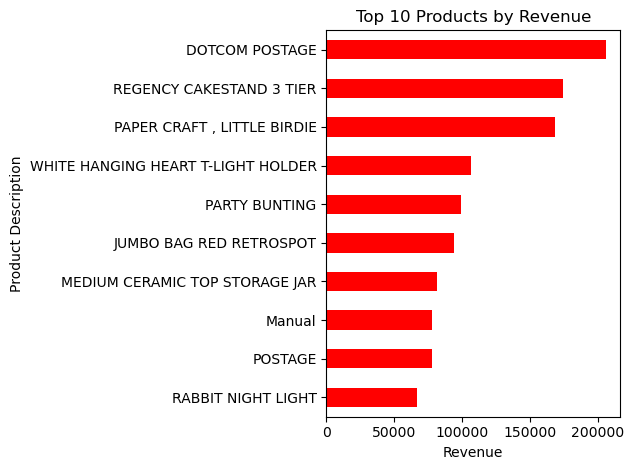

          InvoiceDate YearMonth  Revenue
0 2010-12-01 08:26:00   2010-12    15.30
1 2010-12-01 08:26:00   2010-12    20.34
2 2010-12-01 08:26:00   2010-12    22.00
3 2010-12-01 08:26:00   2010-12    20.34
4 2010-12-01 08:26:00   2010-12    20.34
YearMonth
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Revenue, dtype: float64


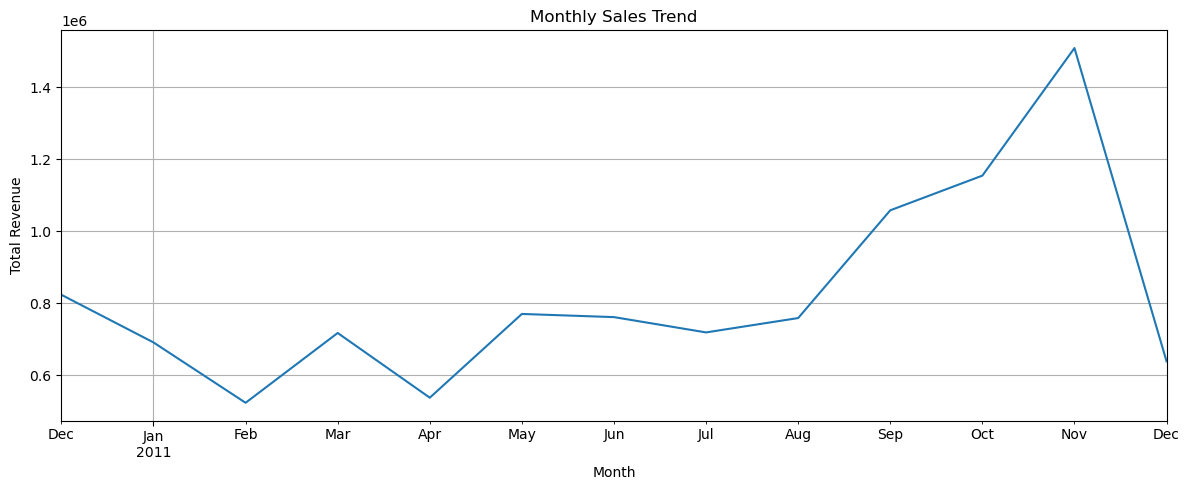

In [33]:
#Identifying the top 10 products with highest sales
top_10 = sales_df.groupby("Description")['Revenue'].sum().sort_values(ascending=False).head(10)
print("Top 10 Products are:\n",top_10)
#Visualizing the top 10 products
import matplotlib.pyplot as plt
top_10.sort_values().plot(kind='barh',color='red')
plt.title("Top 10 Products by Revenue")
plt.xlabel('Revenue')
plt.ylabel('Product Description')

plt.tight_layout()
plt.show()


          InvoiceDate YearMonth  Revenue
0 2010-12-01 08:26:00   2010-12    15.30
1 2010-12-01 08:26:00   2010-12    20.34
2 2010-12-01 08:26:00   2010-12    22.00
3 2010-12-01 08:26:00   2010-12    20.34
4 2010-12-01 08:26:00   2010-12    20.34
YearMonth
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Revenue, dtype: float64


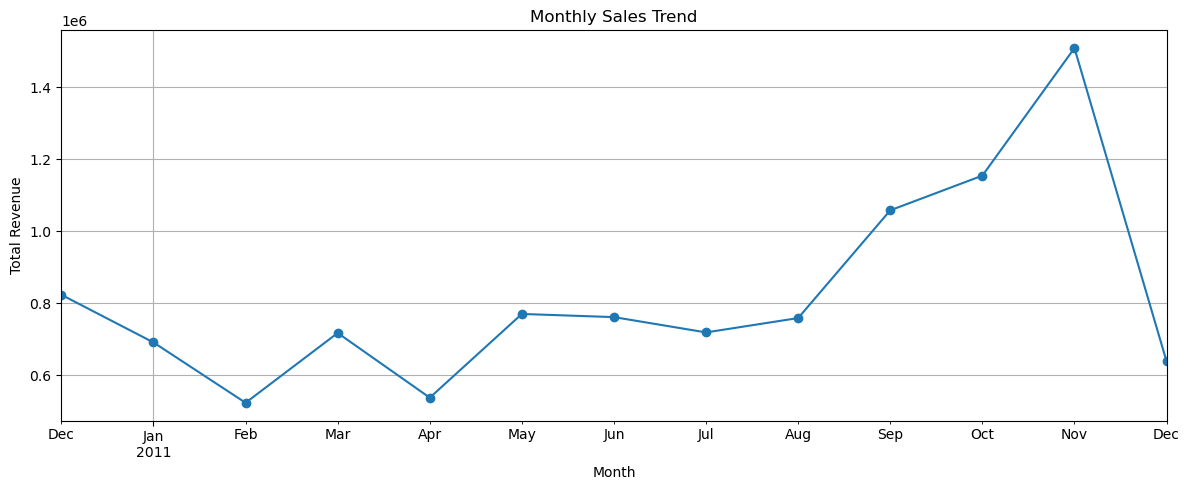

Highest Revenue Month: 2011-11
Highest Revenue: 1509496.33
Lowest Revenue Month: 2011-02
Lowest Revenue: 523631.89


In [36]:
#Monthly Sales Trends
##Business question2: Which months generate the highest revenue?
sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])

sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

print(sales_df[["InvoiceDate", "YearMonth", "Revenue"]].head())

#Groups 
monthly_sales = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
)

print(monthly_sales)
#Visualizing Monthly Sales
monthly_sales.plot(kind="line", figsize=(12, 5),marker='o')

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.grid(True)

plt.tight_layout()
plt.show()

#Analzing highest months and lowest months
highest_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

print("Highest Revenue Month:", highest_month)
print("Highest Revenue:", monthly_sales.max())

print("Lowest Revenue Month:", lowest_month)
print("Lowest Revenue:", monthly_sales.min())